## 1. Carregamento e inspeção inicial

Esta célula importa as bibliotecas utilizadas e carrega as bases climática, de perdas de água e de renda. O objetivo é preparar os dados para a análise e visualizar os primeiros registros de cada fonte.

In [ ]:
import pandas as pd
import geopandas as gpd
import requests
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import skew, kurtosis
from sklearn.impute import KNNImputer
from sklearn.preprocessing import StandardScaler
from mpl_toolkits.mplot3d import Axes3D
from scipy import stats
df_clima = pd.read_csv('dias_consecutivos_seca_sp_2022.csv')
df_agua = pd.read_csv(
    'perdaDeAgua.csv',
    sep=';',
    encoding='latin1',
    skiprows=1,
    header=None,
    names=[
        'id_municipio',
        'municipio',
        'estado',
        'ano_referencia',
        'id_prestador',
        'prestador',
        'sigla_prestador',
        'abrangencia',
        'tipo_servico',
        'natureza_juridica',
        'indice_perdas_distribuicao'
    ],
    usecols=range(11),
    decimal=','
)
df_renda = pd.read_csv(
    'rendaPerCapitaSP.csv',
    skiprows=6,
    header=None,
    names=['id_municipio', 'municipio', 'grupo_idade', 'renda_per_capita'],
    encoding='utf-8-sig'
)

# Inspecionando as colunas e os primeiros registros
display("--- Dados Climáticos (CDD) ---", df_clima.head())
display("--- Dados de Perda de Água (SNIS) ---", df_agua.head())
display("--- Dados de Renda (IBGE) ---", df_renda.head())

'--- Dados Climáticos (CDD) ---'

,id_municipio,max_dias_consecutivos_seca
0,3506003,25
1,3504503,61
2,3521002,17
3,3522406,40
4,3542305,8


'--- Dados de Perda de Água (SNIS) ---'

,id_municipio,municipio,estado,ano_referencia,id_prestador,prestador,sigla_prestador,abrangencia,tipo_servico,natureza_juridica,indice_perdas_distribuicao
0,350010,Adamantina,SP,2022,35503000,Companhia de Saneamento Básico do Estado de Sã...,SABESP,Regional,Água e Esgoto,Sociedade de economia mista com administração ...,23.85
1,350020,Adolfo,SP,2022,35503000,Companhia de Saneamento Básico do Estado de Sã...,SABESP,Regional,Água e Esgoto,Sociedade de economia mista com administração ...,9.72
2,350030,Aguaí,SP,2022,35503000,Companhia de Saneamento Básico do Estado de Sã...,SABESP,Regional,Água e Esgoto,Sociedade de economia mista com administração ...,66.99
3,350040,Águas da Prata,SP,2022,35503000,Companhia de Saneamento Básico do Estado de Sã...,SABESP,Regional,Água e Esgoto,Sociedade de economia mista com administração ...,35.38
4,350050,Águas de Lindóia,SP,2022,35005011,Saneamento Ambiental de Águas de Lindóia,SAAE,Local,Água e Esgoto,Autarquia,40.03


'--- Dados de Renda (IBGE) ---'

,id_municipio,municipio,grupo_idade,renda_per_capita
0,3500105,Adamantina (SP),Total,1868.26
1,3500204,Adolfo (SP),Total,1514.80
2,3500303,Aguaí (SP),Total,1321.67
3,3500402,Águas da Prata (SP),Total,1684.99
4,3500501,Águas de Lindóia (SP),Total,1742.52


O uso de latin1 e utf-8-sig garante a leitura correta de acentuação e caracteres especiais em português, enquanto os parâmetros de mapeamento de colunas evitam erros estruturais no carregamento das tabelas tabulares.

## 3. Aplicação da otimização e inspeção de nulos

Esta etapa aplica a redução de memória às três bases, define a chave municipal e exibe os valores ausentes. O objetivo é padronizar os dados e identificar problemas que precisam de tratamento.

In [156]:
coluna_chave = 'id_municipio' 

# Verificação inicial de nulos e tipos (MCAR, MAR, MNAR)
print("--- Nulos no Clima --- \n", df_clima.isna().sum())
print("--- Nulos na Água --- \n", df_agua.isna().sum())
print("--- Nulos na Renda --- \n", df_renda.isna().sum())

--- Nulos no Clima --- 
 id_municipio                  0
max_dias_consecutivos_seca    0
dtype: int64
--- Nulos na Água --- 
 id_municipio                  0
municipio                     0
estado                        0
ano_referencia                0
id_prestador                  0
prestador                     0
sigla_prestador               0
abrangencia                   0
tipo_servico                  0
natureza_juridica             0
indice_perdas_distribuicao    4
dtype: int64
--- Nulos na Renda --- 
 id_municipio         1
municipio           10
grupo_idade         17
renda_per_capita    17
dtype: int64


### Interpretação dos resultados

A otimização de memória foi aplicada às três bases sem alteração relevante no tamanho apresentado, pois os arquivos são pequenos. A base climática não possui valores ausentes nas colunas analisadas, indicando que está completa para essa etapa.

Na base de perdas de água, foram identificados 4 valores ausentes na coluna `indice_perdas_distribuicao`. Como essa variável é essencial para as análises de eficiência do saneamento, esses registros serão removidos na etapa de limpeza.

Na base de renda, há 17 valores ausentes em `renda_per_capita`, 10 em `municipio` e 1 em `id_municipio`. Os registros sem renda ou sem identificador municipal também serão removidos, pois não podem ser utilizados com segurança nas análises ou nos cruzamentos entre as bases.

Assim, a próxima etapa consiste em tratar esses valores ausentes e manter apenas os registros com informações essenciais para a integração dos dados.

## 4. Remoção de registros incompletos

Esta célula elimina os registros sem valores essenciais nas bases de água e renda e ajusta o tipo do identificador municipal. O objetivo é evitar falhas nas análises e nos cruzamentos posteriores.

In [157]:
# Removendo os 4 nulos do índice de perdas
df_agua.dropna(subset=['indice_perdas_distribuicao'], inplace=True)

# Removendo os 17 nulos da renda e 1 nulo do id_municipio
df_renda.dropna(subset=['renda_per_capita', 'id_municipio'], inplace=True)

# O id_municipio no df_renda provavelmente virou float por causa do nulo, vamos garantir que seja int64
df_renda['id_municipio'] = df_renda['id_municipio'].astype('int64')

print(f"Linhas restantes em Água: {len(df_agua)}")
print(f"Linhas restantes em Renda: {len(df_renda)}")

Linhas restantes em Água: 643
Linhas restantes em Renda: 645


### Interpretação dos resultados

Após a remoção dos valores ausentes, a base de perdas de água passou a conter **643 linhas**. Isso significa que os 4 registros sem valor em `indice_perdas_distribuicao` foram excluídos, pois não poderiam contribuir para as análises de eficiência do saneamento.

A base de renda passou a conter **645 linhas**. Foram removidos os registros sem `renda_per_capita` e o registro sem `id_municipio`, já que essas informações são necessárias para comparar os municípios e realizar os cruzamentos entre as bases.

Por fim, `id_municipio` foi convertido para `int64` após a remoção dos valores ausentes. Essa padronização evita problemas de tipo durante os merges e garante que os identificadores municipais sejam tratados como códigos inteiros nas etapas seguintes.

## 5. Identificação de outliers

Esta célula calcula os limites do intervalo interquartil e identifica valores extremos nas variáveis de renda, perdas de água e dias secos. O objetivo é avaliar a presença e a proporção de outliers.

In [ ]:
def verificar_outliers_iqr(df, coluna):
    Q1 = df[coluna].quantile(0.25)
    Q3 = df[coluna].quantile(0.75)
    IQR = Q3 - Q1
    
    limite_inferior = Q1 - 1.5 * IQR
    limite_superior = Q3 + 1.5 * IQR
    
    # Filtra apenas os registros que estão fora dos limites
    outliers = df[(df[coluna] < limite_inferior) | (df[coluna] > limite_superior)]
    percentual = (len(outliers) / len(df)) * 100
    
    print(f"-> {coluna}: {len(outliers)} outliers identificados ({percentual:.2f}% da base)")
    
    display(outliers.sort_values(by=coluna, ascending=False).head())

print("=== Verificação Estatística de Outliers (Método IQR) ===")
verificar_outliers_iqr(df_renda, 'renda_per_capita')
verificar_outliers_iqr(df_agua, 'indice_perdas_distribuicao')
verificar_outliers_iqr(df_clima, 'max_dias_consecutivos_seca')

=== Verificação Estatística de Outliers (Método IQR) ===
-> renda_per_capita: 24 outliers identificados (3.72% da base)


,id_municipio,municipio,grupo_idade,renda_per_capita
545,3548807,São Caetano do Sul (SP),Total,3884.58
528,3547304,Santana de Parnaíba (SP),Total,3465.07
636,3556701,Vinhedo (SP),Total,3247.77
542,3548500,Santos (SP),Total,3237.52
629,3556206,Valinhos (SP),Total,3127.28


-> indice_perdas_distribuicao: 16 outliers identificados (2.49% da base)


,id_municipio,municipio,estado,ano_referencia,id_prestador,prestador,sigla_prestador,abrangencia,tipo_servico,natureza_juridica,indice_perdas_distribuicao
364,353230,Natividade da Serra,SP,2022,35323011,Prefeitura Municipal de Natividade da Serra,PMNS,Local,Água e Esgoto,Administração pública direta,89.63
334,352950,Mendonça,SP,2022,35295011,Prefeitura Municipal de Mendonça,PMM,Local,Água e Esgoto,Administração pública direta,80.08
457,354075,Potim,SP,2022,35407512,Águas de Potim SPE LTDA,AP,Local,Água e Esgoto,Empresa privada,76.58
241,352090,Ipaussu,SP,2022,35209011,Prefeitura Municipal de Ipaussu,PMI,Local,Água e Esgoto,Administração pública direta,76.35
119,351040,Capivari,SP,2022,35104011,Serviço Autônomo de Água e Esgoto,SAAE,Local,Água e Esgoto,Autarquia,75.39


-> max_dias_consecutivos_seca: 2 outliers identificados (5.26% da base)


,id_municipio,max_dias_consecutivos_seca
16,3535101,270
5,3505302,95


### Interpretação dos resultados

A análise pelo método do intervalo interquartil (IQR) identificou **24 outliers na renda per capita**, correspondendo a aproximadamente **3,72% da base**. Os maiores valores exibidos pertencem a municípios com renda acima do padrão central observado, no caso: **São Caetano do Sul**, **Santana de Parnaíba**, **Vinhedo**, **Santos** e **Valinhos**.

Na variável de perdas de água, foram encontrados **16 outliers**, equivalentes a aproximadamente **2,49% da base**. Os maiores valores exibidos indicam municípios com índices de perdas significativamente superiores, no caso: **Natividade da Serra**, **Mendonça**, **Potim**, **Ipaussu** e **Capivari**.

Na base climática bruta, osvalor de **270 dias consecutivos secos** aparece como um outlier extremamente elevado e irrealista. Ele será tratado na etapa seguinte, que aplica o filtro de valores acima de 150 dias antes das análises posteriores.

## 6. Visualização dos outliers

Esta célula cria boxplots comparativos para renda, perdas de água e dias consecutivos secos. O objetivo é visualizar a dispersão e os valores extremos encontrados na etapa anterior.

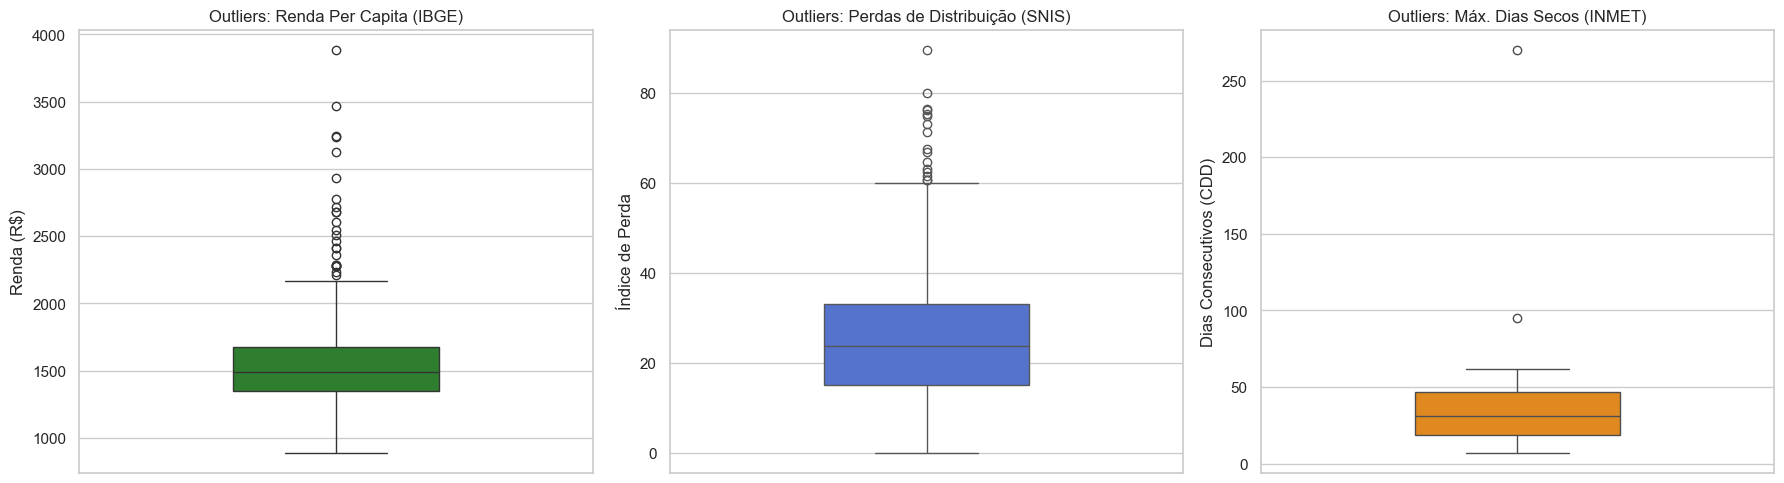

In [159]:
# Criando uma figura com 3 gráficos (subplots) lado a lado
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Boxplot da Renda Per Capita
sns.boxplot(y=df_renda['renda_per_capita'], ax=axes[0], color='forestgreen', width=0.4)
axes[0].set_title('Outliers: Renda Per Capita (IBGE)')
axes[0].set_ylabel('Renda (R$)')

# 2. Boxplot das Perdas de Distribuição
sns.boxplot(y=df_agua['indice_perdas_distribuicao'], ax=axes[1], color='royalblue', width=0.4)
axes[1].set_title('Outliers: Perdas de Distribuição (SNIS)')
axes[1].set_ylabel('Índice de Perda')

# 3. Boxplot do Clima (CDD)
sns.boxplot(y=df_clima['max_dias_consecutivos_seca'], ax=axes[2], color='darkorange', width=0.4)
axes[2].set_title('Outliers: Máx. Dias Secos (INMET)')
axes[2].set_ylabel('Dias Consecutivos (CDD)')

# Ajusta o espaçamento para não sobrepor os títulos
plt.tight_layout()
plt.show()

### Interpretação dos boxplots

Os boxplots confirmam a presença de valores extremos nas três variáveis analisadas.

- **Renda per capita:** a maior parte dos municípios está concentrada aproximadamente entre R$ 1.350 e R$ 1.700, mas há diversos valores acima do limite superior, incluindo observações próximas de R$ 3.900. Isso indica uma distribuição assimétrica à direita, com municípios de renda muito superior ao padrão central.
- **Perdas de água:** os valores centrais estão aproximadamente entre 15% e 33%, enquanto vários municípios aparecem acima de 60%, chegando a valores próximos de 90%
- **Dias consecutivos secos:** a maior parte dos valores está entre aproximadamente 7 e 62 dias, com um ponto extremo próximo de 95 dias, e o ponto mais extremo em 250 dias. Esse município apresenta um comportamento climático bastante diferente do restante da amostra.

## 7. Tratamento de valores extremos

Esta célula remove um valor climático considerado implausível e define uma função de capping pelo IQR para limitar valores extremos de renda e perdas. O objetivo é reduzir a influência de observações atípicas sem eliminar municípios desnecessariamente.

In [ ]:
# 1. TRATAMENTO DO CLIMA 
# Cortamos qualquer registro com mais de 150 dias sem chuva (que elimina aquele ponto de >250)
df_clima = df_clima[df_clima['max_dias_consecutivos_seca'] < 150]

# 2. TRATAMENTO DE RENDA E PERDAS (Winsorização / Capping)
# Essa função não deleta o município, apenas "tosa" o valor extremo no limite do bigode do boxplot
def aplicar_capping_iqr(df, coluna):
    Q1 = df[coluna].quantile(0.25)
    Q3 = df[coluna].quantile(0.75)
    IQR = Q3 - Q1
    limite_superior = Q3 + 1.5 * IQR
    
    # Substitui os valores acima do limite pelo próprio valor do limite
    df[coluna] = np.where(df[coluna] > limite_superior, limite_superior, df[coluna])
    return df


### Interpretação do tratamento de valores extremos

A etapa remove registros climáticos com mais de 150 dias consecutivos secos, considerados incompatíveis com o comportamento esperado da amostra e potencialmente associados a erro ou valor extremo não representativo. Para renda e perdas de água, a função de capping limita valores acima do limite superior do IQR sem excluir os municípios.

Essa abordagem preserva os registros e reduz a influência de extremos nas análises posteriores. O impacto do capping deve ser avaliado comparando as estatísticas antes e depois do tratamento.

## 8. Estatísticas descritivas e histogramas

Esta célula calcula estatísticas resumidas e constrói histogramas das principais variáveis. O objetivo é compreender a distribuição dos dados antes das análises multivariadas.

'Estatísticas - Renda (IBGE):'

count     645.00
mean     1543.42
std       330.19
min       888.50
25%      1348.69
50%      1487.79
75%      1677.47
max      3884.58
Name: renda_per_capita, dtype: float64

'Estatísticas - Perdas (SNIS):'

count    643.00
mean      25.46
std       14.51
min        0.00
25%       15.17
50%       23.85
75%       33.15
max       89.63
Name: indice_perdas_distribuicao, dtype: float64

'Estatísticas - Clima (INMET):'

count    37.00
mean     32.86
std      18.89
min       7.00
25%      18.00
50%      30.00
75%      42.00
max      95.00
Name: max_dias_consecutivos_seca, dtype: float64

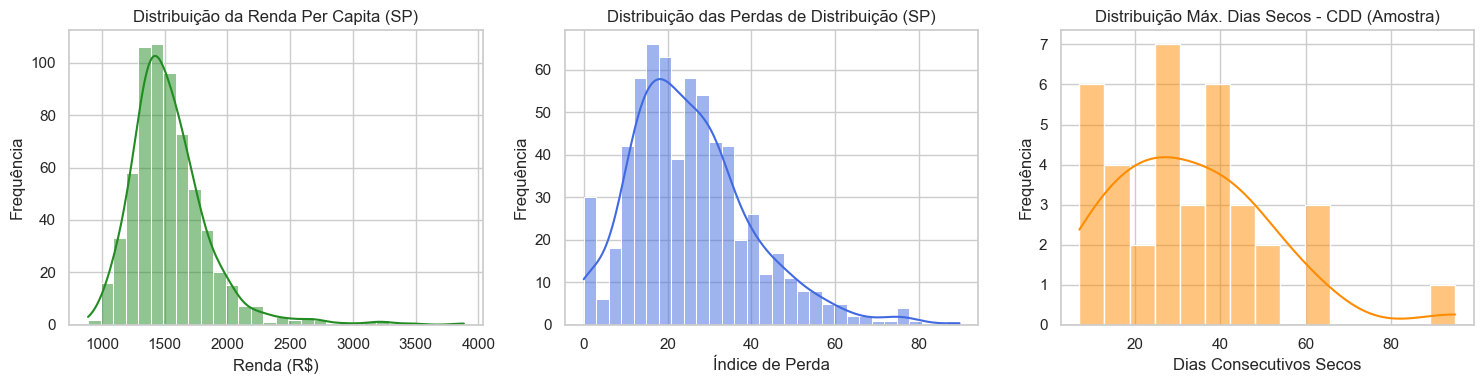

In [161]:
sns.set_theme(style="whitegrid")

# 1. Estatísticas Descritivas
display("Estatísticas - Renda (IBGE):", df_renda['renda_per_capita'].describe().round(2))
display("Estatísticas - Perdas (SNIS):", df_agua['indice_perdas_distribuicao'].describe().round(2))
display("Estatísticas - Clima (INMET):", df_clima['max_dias_consecutivos_seca'].describe().round(2))

# 2. Histogramas (Grid 1x3)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Histograma: Renda
sns.histplot(df_renda['renda_per_capita'], bins=30, kde=True, ax=axes[0], color='forestgreen')
axes[0].set_title('Distribuição da Renda Per Capita (SP)')
axes[0].set_xlabel('Renda (R$)')
axes[0].set_ylabel('Frequência')

# Histograma: Perdas
sns.histplot(df_agua['indice_perdas_distribuicao'], bins=30, kde=True, ax=axes[1], color='royalblue')
axes[1].set_title('Distribuição das Perdas de Distribuição (SP)')
axes[1].set_xlabel('Índice de Perda')
axes[1].set_ylabel('Frequência')

# Histograma: Clima
sns.histplot(df_clima['max_dias_consecutivos_seca'], bins=15, kde=True, ax=axes[2], color='darkorange')
axes[2].set_title('Distribuição Máx. Dias Secos - CDD (Amostra)')
axes[2].set_xlabel('Dias Consecutivos Secos')
axes[2].set_ylabel('Frequência')

plt.tight_layout()
plt.show()

### Interpretação das distribuições

Os histogramas mostram que as três variáveis possuem comportamentos diferentes:

- **Renda per capita:** apresenta maior concentração aproximadamente entre R$ 1.300 e R$ 1.700, com uma cauda longa à direita.Também com média de aproximadamente R$ 1.543 e desvio padrão de R$ 330.
- **Perdas de água:** concentra-se principalmente entre 10% e 35%, mas possui uma cauda à direita com municípios que alcançam perdas próximas de 90%. Esses valores confirmam a presença de situações operacionais muito acima do padrão predominante.
- **Dias consecutivos secos:** A maior parte dos valores está entre 10 e 50 dias, mas há um registro maior de 80 dias.

## 9. Assimetria e curtose

Esta célula calcula a assimetria e a curtose das variáveis numéricas. O objetivo é avaliar o formato das distribuições e identificar possíveis caudas longas ou concentração de valores extremos.

In [179]:
def analise_forma(df, coluna, nome_dataset):
    assimetria = skew(df[coluna].dropna())
    curt = kurtosis(df[coluna].dropna())
    
    print(f"--- {nome_dataset} ({coluna}) ---")
    print(f"Assimetria (Skewness): {assimetria:.2f} " 
          f"-> {'> 0 (Cauda à direita, muitos valores baixos)' if assimetria > 0 else '< 0 (Cauda à esquerda)'}")
    print(f"Curtose (Kurtosis): {curt:.2f} "
          f"-> {'> 3 (Muitos outliers pesados)' if curt > 3 else '< 3 (Poucos outliers extremos)'}\n")

analise_forma(df_renda, 'renda_per_capita', 'IBGE')
analise_forma(df_agua, 'indice_perdas_distribuicao', 'SNIS')
analise_forma(df_clima, 'max_dias_consecutivos_seca', 'INMET')

--- IBGE (renda_per_capita) ---
Assimetria (Skewness): 2.14 -> > 0 (Cauda à direita, muitos valores baixos)
Curtose (Kurtosis): 8.86 -> > 3 (Muitos outliers pesados)

--- SNIS (indice_perdas_distribuicao) ---
Assimetria (Skewness): 0.90 -> > 0 (Cauda à direita, muitos valores baixos)
Curtose (Kurtosis): 1.32 -> < 3 (Poucos outliers extremos)

--- INMET (max_dias_consecutivos_seca) ---
Assimetria (Skewness): 0.94 -> > 0 (Cauda à direita, muitos valores baixos)
Curtose (Kurtosis): 1.37 -> < 3 (Poucos outliers extremos)



### Interpretação da assimetria e da curtose

A análise mostra **assimetria positiva nas três variáveis**, indicando distribuições com cauda à direita: a maioria dos municípios concentra-se em valores mais baixos ou intermediários, enquanto poucos municípios apresentam valores muito elevados.

- **Renda per capita:** assimetria de **2,14** e curtose de **8,86**. É a distribuição mais assimétrica e com cauda mais pesada, confirmando a influência de municípios com rendas muito acima do padrão central e a presença de muitos outliers.
- **Perdas de água:** assimetria de **0,90** e curtose de **1,32**. Há uma cauda à direita causada por municípios com perdas elevadas, mas a curtose indica que a concentração de extremos não é tão intensa quanto na renda.
- **Dias consecutivos secos:** assimetria de **0,94** e curtose de **1,37**. A distribuição também possui cauda à direita, com alguns municípios apresentando períodos de seca mais longos, mas sem uma concentração tão forte de valores extremos quanto na renda.

 A curtose utilizada pela função corresponde à versão em excesso: valores próximos de 0 representam uma distribuição semelhante à normal, enquanto valores positivos maiores indicam caudas mais pesadas.

## 10. Curvas de distribuição acumulada

Esta célula gera curvas ECDF (Empirical Cumulative Distribution Function ou Função de Distribuição Acumulada Empírica, uma ferramenta estatística que mostra a proporção de observações em um conjunto de dados que são menores ou iguais a um determinado valor) para renda, perdas de água e dias secos. O objetivo é comparar a proporção acumulada dos municípios e observar diferenças de distribuição entre as variáveis.

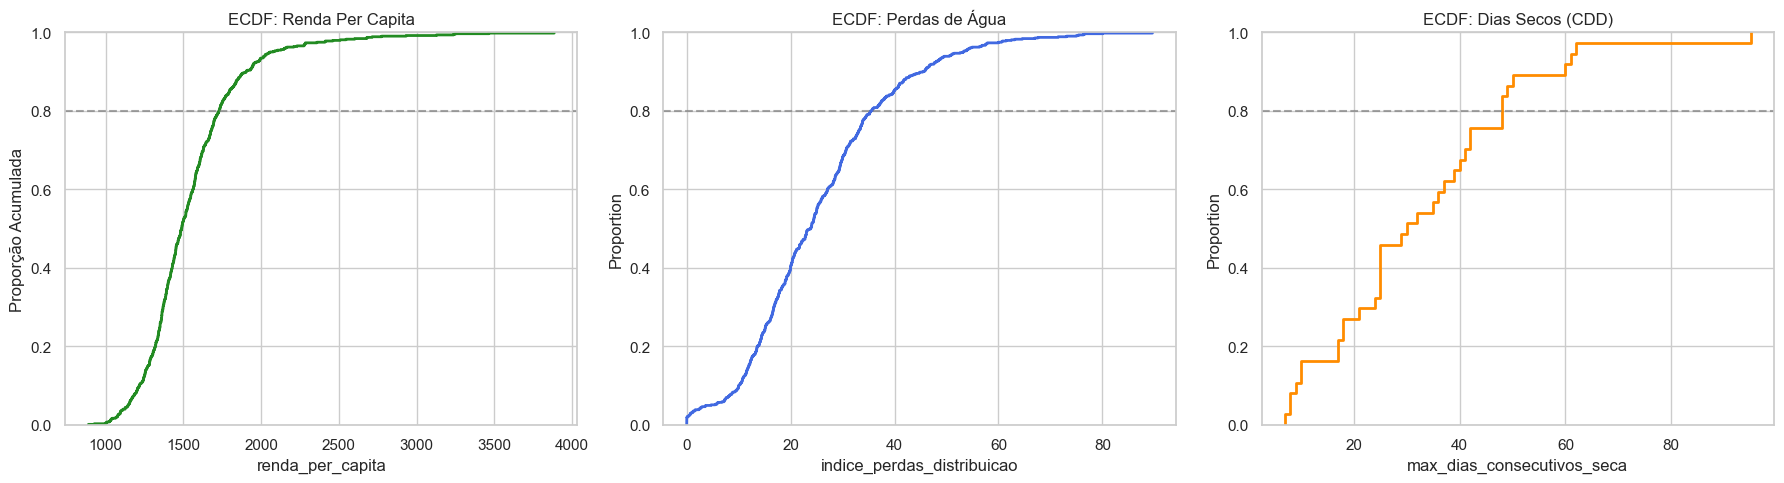

In [163]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# ECDF Renda
sns.ecdfplot(data=df_renda, x='renda_per_capita', ax=axes[0], color='forestgreen', lw=2)
axes[0].set_title('ECDF: Renda Per Capita')
axes[0].set_ylabel('Proporção Acumulada')
axes[0].axhline(0.8, color='gray', linestyle='--', alpha=0.7) # Linha marcando os 80%

# ECDF Perdas
sns.ecdfplot(data=df_agua, x='indice_perdas_distribuicao', ax=axes[1], color='royalblue', lw=2)
axes[1].set_title('ECDF: Perdas de Água')
axes[1].axhline(0.8, color='gray', linestyle='--', alpha=0.7)

# ECDF Clima
sns.ecdfplot(data=df_clima, x='max_dias_consecutivos_seca', ax=axes[2], color='darkorange', lw=2)
axes[2].set_title('ECDF: Dias Secos (CDD)')
axes[2].axhline(0.8, color='gray', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

### Interpretação da distribuição acumulada

A renda apresenta concentração em valores baixos e intermediários, com uma cauda prolongada causada pelos municípios de maior renda. As perdas de água também acumulam a maior parte dos casos em níveis baixos e médios, mas possuem uma parcela menor com índices elevados. A curva de dias secos evidencia a maior variabilidade climática e a presença de municípios com períodos de estiagem mais longos.

## 11. Padronização das categorias jurídicas

Esta célula substitui descrições longas de natureza jurídica por categorias mais curtas e consistentes. O objetivo é facilitar a leitura das tabelas e dos gráficos comparativos.

In [164]:
mapeamento_juridico = {
    'Sociedade de economia mista com administração pública': 'Soc. Econ. Mista com Adm. Púb.', # Pega o valor atual e altera para o novo
    'Administração pública direta': 'Adm. Púb. Direta'
}

df_agua['natureza_juridica'] = df_agua['natureza_juridica'].replace(mapeamento_juridico)

### Interpretação da padronização jurídica

As categorias de natureza jurídica foram simplificadas para facilitar a leitura das tabelas e gráficos. A alteração é apenas semântica: os registros não foram removidos nem tiveram seus valores numéricos modificados. Essa padronização permite comparar de forma mais clara os modelos de gestão dos prestadores.

## 12. Perdas por natureza jurídica

Esta célula agrupa as perdas de água por natureza jurídica e apresenta médias, medianas, contagens e um gráfico de violino. O objetivo é comparar o desempenho dos diferentes modelos de gestão.

'Perdas de Água agrupadas por Natureza Jurídica do Prestador:'

,mean,median,count
natureza_juridica,,,
Autarquia,33.83,33.42,85
Empresa privada,28.85,27.72,28
Adm. Púb. Direta,25.65,20.53,150
Soc. Econ. Mista com Adm. Púb.,23.26,22.03,379
Empresa pública,23.04,23.04,1


C:\Users\Du\AppData\Local\Temp\ipykernel_33836\21740098.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df_agua, x='natureza_juridica', y='indice_perdas_distribuicao', palette='muted')


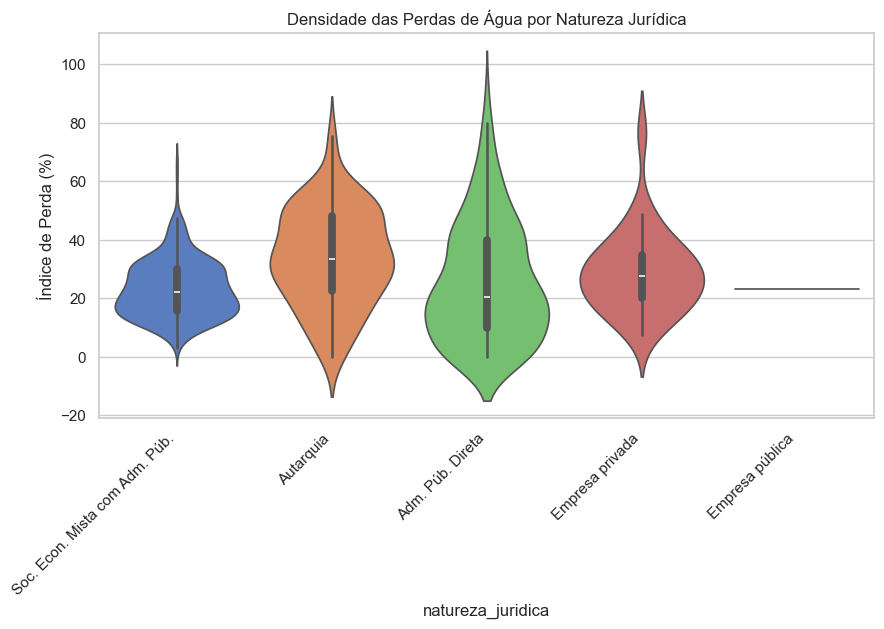

In [165]:

# Analisando a perda média de água pelo tipo de Natureza Jurídica do prestador
agrupamento_juridico = df_agua.groupby('natureza_juridica')['indice_perdas_distribuicao'].agg(['mean', 'median', 'count']).sort_values(by='mean', ascending=False)
display("Perdas de Água agrupadas por Natureza Jurídica do Prestador:", agrupamento_juridico.round(2))

# Gráfico de violino (Boxplot mais avançado que mostra a densidade)
plt.figure(figsize=(10, 5))
sns.violinplot(data=df_agua, x='natureza_juridica', y='indice_perdas_distribuicao', palette='muted')
plt.title('Densidade das Perdas de Água por Natureza Jurídica')
plt.xticks(rotation=45, ha='right')
plt.ylabel('Índice de Perda (%)')
plt.show()

### Interpretação das perdas por natureza jurídica

As maiores perdas médias aparecem entre as **autarquias**, com média de **33,83%**, seguidas pelas empresas privadas, com **28,85%**, e pela administração pública direta, com **25,65%**. As sociedades de economia mista com administração pública apresentam média de **23,26%**, a menor entre os grupos com quantidade relevante de observações.

A comparação deve considerar também o tamanho das amostras: sociedades de economia mista possuem 379 registros, administração pública direta 150, autarquias 85 e empresas privadas 28. A categoria empresa pública possui apenas 1 registro e não permite uma conclusão geral. O gráfico de violino reforça que a dispersão varia entre os modelos de gestão.

## 13. Rankings de perdas e renda

Esta célula lista os municípios com maiores perdas de água e menores rendas per capita. O objetivo é destacar casos prioritários para investigação e interpretação.

In [166]:
# Os 5 piores em perdas de água
display("Top 5 Municípios com MAIOR perda de água:", 
        df_agua[['municipio', 'indice_perdas_distribuicao', 'prestador']].sort_values(by='indice_perdas_distribuicao', ascending=False).head())

# Os 5 com menor renda
display("Top 5 Municípios com MENOR renda per capita:", 
        df_renda[['municipio', 'renda_per_capita']].sort_values(by='renda_per_capita', ascending=True).head())

'Top 5 Municípios com MAIOR perda de água:'

,municipio,indice_perdas_distribuicao,prestador
364,Natividade da Serra,89.63,Prefeitura Municipal de Natividade da Serra
334,Mendonça,80.08,Prefeitura Municipal de Mendonça
457,Potim,76.58,Águas de Potim SPE LTDA
241,Ipaussu,76.35,Prefeitura Municipal de Ipaussu
119,Capivari,75.39,Serviço Autônomo de Água e Esgoto


'Top 5 Municípios com MENOR renda per capita:'

,municipio,renda_per_capita
60,Barra do Chapéu (SP),888.50
368,Nova Campina (SP),926.06
91,Buri (SP),996.87
577,Sete Barras (SP),1004.06
253,Itaoca (SP),1008.01


### Interpretação dos rankings

Os maiores índices de perdas foram observados em **Natividade da Serra (89,63%)**, **Mendonça (80,08%)**, **Potim (76,58%)**, **Ipaussu (76,35%)** e **Capivari (75,39%)**. Esses municípios devem ser considerados prioritários para investigar possíveis problemas de operação, infraestrutura ou medição.

Os menores valores de renda per capita foram encontrados em **Barra do Chapéu (R$ 888,50)**, **Nova Campina (R$ 926,06)**, **Buri (R$ 996,87)**, **Sete Barras (R$ 1.004,06)** e **Itaoca (R$ 1.008,01)**. Esses rankings são descritivos e não indicam, sozinhos, relação causal entre renda e perdas.

## 14. Renda por grupo de idade

Esta célula verifica as categorias etárias disponíveis e compara a renda média entre elas. O objetivo é entender como a composição etária se relaciona com a renda observada.

"Categorias de 'grupo_idade':"

grupo_idade
Total    645
Name: count, dtype: int64

C:\Users\Du\AppData\Local\Temp\ipykernel_33836\795145010.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_renda, x='grupo_idade', y='renda_per_capita', errorbar='sd', palette='viridis')


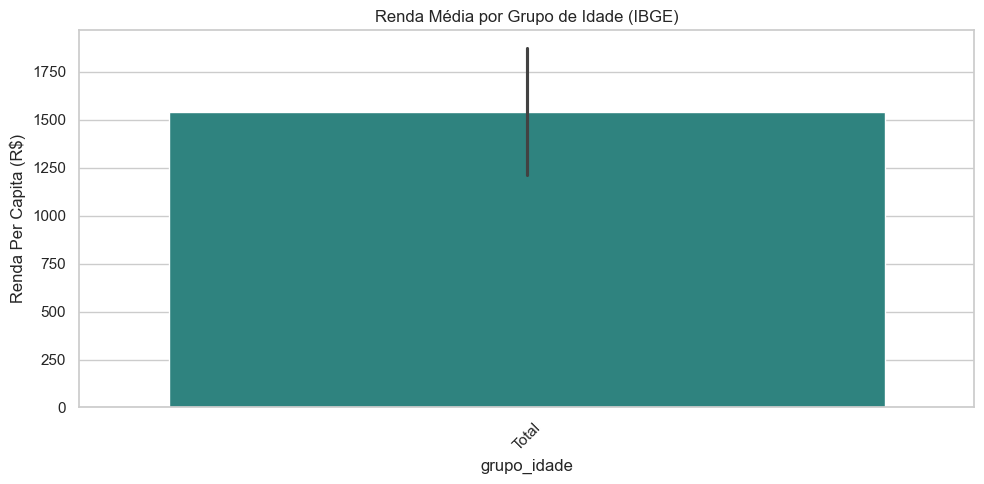

In [167]:
# 1. Verificar quais são as faixas etárias presentes
display("Categorias de 'grupo_idade':", df_renda['grupo_idade'].value_counts())

# 2. Distribuição da Renda por Grupo de Idade
plt.figure(figsize=(10, 5))
sns.barplot(data=df_renda, x='grupo_idade', y='renda_per_capita', errorbar='sd', palette='viridis')
plt.title('Renda Média por Grupo de Idade (IBGE)')
plt.xticks(rotation=45)
plt.ylabel('Renda Per Capita (R$)')
plt.tight_layout()
plt.show()

### Interpretação da renda por grupo de idade

A base contém somente a categoria **Total**, presente nos 645 registros. Portanto, o gráfico acaba não comparando diferentes faixas etárias, ele apenas resume a distribuição da renda per capita total dos municípios.

## 15. Comparação das perdas por características do serviço

Esta célula compara a perda média por natureza jurídica, abrangência e tipo de serviço. O objetivo é identificar padrões de eficiência entre diferentes configurações de saneamento.

C:\Users\Du\AppData\Local\Temp\ipykernel_33836\3033366919.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_agua, x='natureza_juridica', y='indice_perdas_distribuicao', errorbar=None, palette='mako', ax=axes[0])
C:\Users\Du\AppData\Local\Temp\ipykernel_33836\3033366919.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_agua, x='abrangencia', y='indice_perdas_distribuicao', errorbar=None, palette='flare', ax=axes[1])
C:\Users\Du\AppData\Local\Temp\ipykernel_33836\3033366919.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barp

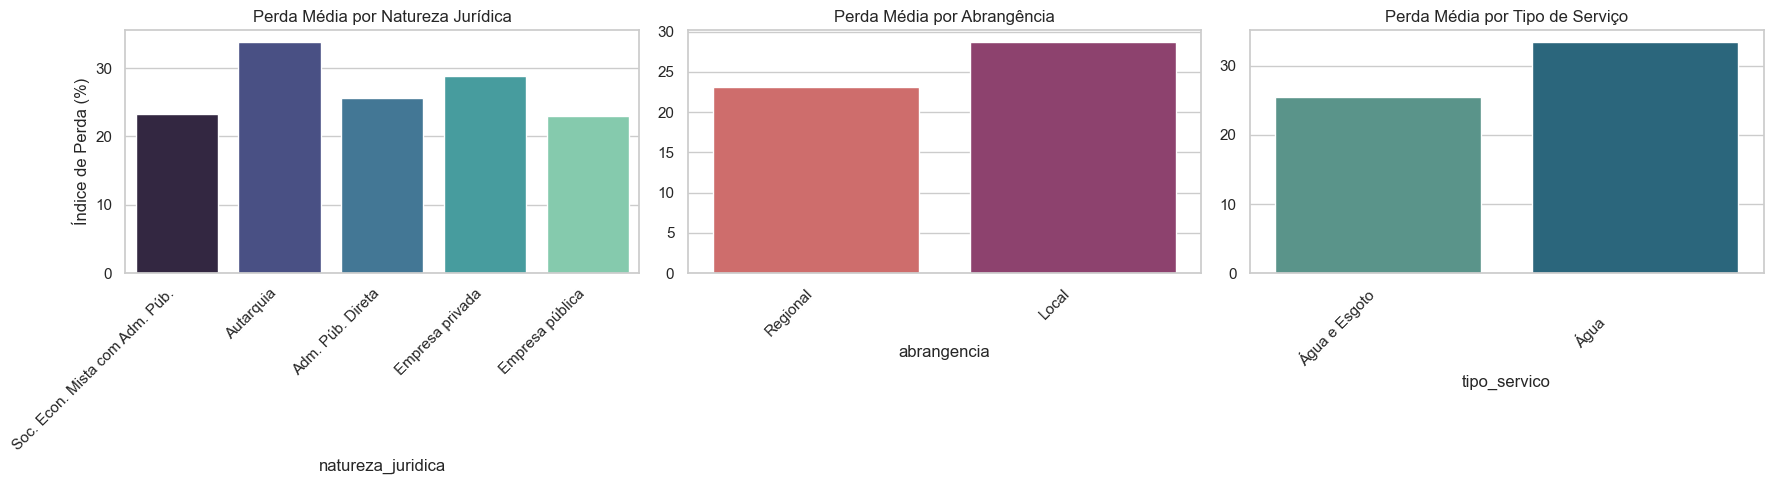

'Top 5 Prestadores de Saneamento (Qtd de Municípios Atendidos):'

sigla_prestador
SABESP    375
SAAE       32
PMI        12
PMC        10
PMP         9
Name: count, dtype: int64

In [168]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Perda x Natureza Jurídica
sns.barplot(data=df_agua, x='natureza_juridica', y='indice_perdas_distribuicao', errorbar=None, palette='mako', ax=axes[0])
axes[0].set_title('Perda Média por Natureza Jurídica')
axes[0].tick_params(axis='x', labelrotation=45)
plt.setp(axes[0].get_xticklabels(), ha='right')
axes[0].set_ylabel('Índice de Perda (%)')

# Perda x Abrangência
sns.barplot(data=df_agua, x='abrangencia', y='indice_perdas_distribuicao', errorbar=None, palette='flare', ax=axes[1])
axes[1].set_title('Perda Média por Abrangência')
axes[1].tick_params(axis='x', labelrotation=45)
plt.setp(axes[1].get_xticklabels(), ha='right')
axes[1].set_ylabel('')

# Perda x Tipo de Serviço
sns.barplot(data=df_agua, x='tipo_servico', y='indice_perdas_distribuicao', errorbar=None, palette='crest', ax=axes[2])
axes[2].set_title('Perda Média por Tipo de Serviço')
axes[2].tick_params(axis='x', labelrotation=45)
plt.setp(axes[2].get_xticklabels(), ha='right')
axes[2].set_ylabel('')

plt.tight_layout()
plt.show()

# Verificando concentração de monopólio: Quem são os 5 maiores prestadores em SP?
display("Top 5 Prestadores de Saneamento (Qtd de Municípios Atendidos):")
display(df_agua['sigla_prestador'].value_counts().head())

### Interpretação das comparações por serviço

A SABESP lidera isoladamente com ampla vantagem, atendendo 375 municípios, seguida por autarquias municipais como o SAAE (32 cidades), evidenciando a dualidade entre grandes operadoras regionais e serviços autônomos locais.

As Autarquias registram a maior média de perdas de água no estado (próxima a 34%), enquanto as empresas públicas e sociedades de economia mista apresentam os menores índices médios (cerca de 23%).

Prestadores com abrangência Regional apresentam perdas médias inferiores (~23%) em relação aos modelos de abrangência Local (~28.5%), sugerindo ganhos de eficiência operacional em redes integradas.

Redes dedicadas exclusivamente ao serviço de Água sofrem perdas médias substancialmente maiores (~33%) do que aquelas que operam o sistema combinado de Água e Esgoto (~25%).

## 16. Integração entre clima e perdas de água

Esta célula cria uma chave municipal compatível, cruza as bases climática, de perdas e de renda e prepara o DataFrame `df_final`. O objetivo é reunir os indicadores necessários para as análises multivariadas.

In [ ]:
# 1. Padronizando a chave usada no merge
df_clima['_chave_merge'] = df_clima['id_municipio'].astype('string').str.strip().str[:6]
df_agua['_chave_merge'] = df_agua['id_municipio'].astype('string').str.strip().str[:6]
df_renda['_chave_merge'] = df_renda['id_municipio'].astype('string').str.strip().str[:6]

# 2. Removendo duplicatas para garantir que o estado tenha exatas 645 linhas
df_clima_limpo = df_clima.drop_duplicates(subset=['_chave_merge'])
df_agua_limpo = df_agua.drop_duplicates(subset=['_chave_merge'])
df_renda_limpo = df_renda.drop_duplicates(subset=['_chave_merge'])

# 3. Merge temporário para trazer o nome da cidade para a tabela de clima
df_clima_nomes = df_clima_limpo.merge(
    df_agua_limpo[['_chave_merge', 'municipio']],
    on='_chave_merge',
    how='inner'
).drop(columns='_chave_merge')

display("Top 10 Cidades mais suscetíveis à seca (Maiores valores de CDD):")
display(df_clima_nomes.sort_values(by='max_dias_consecutivos_seca', ascending=False).head(10))

df_final = (
    df_agua_limpo[
        [
            '_chave_merge',
            'id_municipio',
            'municipio',
            'abrangencia',
            'natureza_juridica',
            'tipo_servico',
            'indice_perdas_distribuicao'
        ]
    ]
    .merge( # Une Água e Renda (preservando tudo com OUTER)
        df_renda_limpo[['_chave_merge', 'renda_per_capita']],
        on='_chave_merge',
        how='outer'
    )
    .merge( # Anexa o Clima (usando LEFT para não apagar cidades sem estação)
        df_clima_limpo[['_chave_merge', 'max_dias_consecutivos_seca']],
        on='_chave_merge',
        how='left'
    )
    .drop(columns='_chave_merge')
)

# 5. Verificações
cidades_criticas = len(df_clima_nomes[df_clima_nomes['max_dias_consecutivos_seca'] > 30])
print(f"\nMunicípios na amostra com mais de 30 dias secos seguidos: {cidades_criticas}")
print(f"Municípios integrados em df_final: {len(df_final)}")

'Top 10 Cidades mais suscetíveis à seca (Maiores valores de CDD):'

,id_municipio,max_dias_consecutivos_seca,municipio
5,3505302,95,Barra Bonita
15,3519600,62,Ibitinga
1,3504503,61,Avaré
27,3555802,60,Urânia
25,3550902,50,São Simão
28,3516200,49,Franca
24,3524105,48,Ituverava
8,3548906,48,São Carlos
7,3527108,48,Lins
10,3539608,42,Planalto



Municípios na amostra com mais de 30 dias secos seguidos: 18
Municípios integrados em df_final: 645


### Interpretação da integração das bases

A integração preservou **645 municípios** no `df_final`. Foram identificados **18 municípios com mais de 30 dias consecutivos secos**, enquanto os demais apresentam valores abaixo desse limite. A chave temporária com seis dígitos permitiu compatibilizar os códigos municipais das bases de clima, água e renda sem alterar os identificadores originais.

Além disso, Barra Bonita lidera com folga o ranking estadual, registrando 95 dias consecutivos sem precipitação na série analisada.

Ibitinga (62 dias), Avaré (61 dias) e Urânia (60 dias) compõem o grupo com maior índice de estresse hídrico climático após o líder.

Municípios como São Simão (50 dias), Franca (49 dias) e o grupo de 48 dias formado por Ituverava, São Carlos e Lins completam as principais posições de exposição à seca prolongada.

## 17. Análise de Dispersão Multivariada por Abrangência do Saneamento

Este código tem o objetivo de gerar uma matriz de gráficos de dispersão e densidade para analisar simultaneamente as interações entre a renda per capita, o índice de perdas de água e o máximo de dias secos, segmentando as observações pela abrangência do serviço de saneamento (local ou regional). Com essa visualização, é possível inspecionar de forma cruzada o comportamento e a distribuição conjunta dessas variáveis no estado.

<Figure size 1200x1000 with 0 Axes>

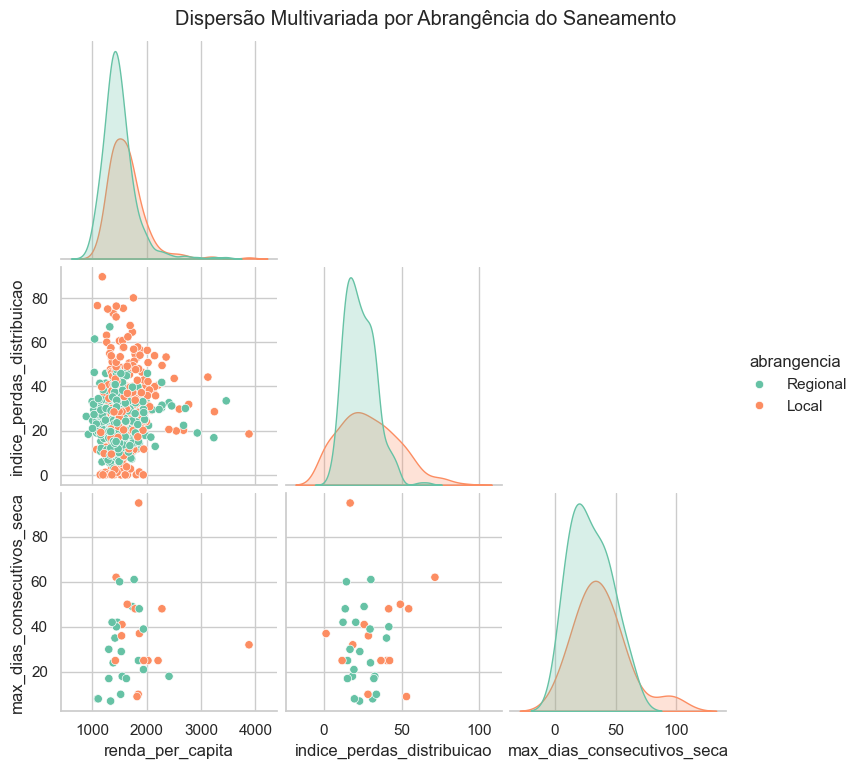

In [170]:
colunas_pairplot = ['renda_per_capita', 'indice_perdas_distribuicao', 'max_dias_consecutivos_seca', 'abrangencia']

plt.figure(figsize=(12, 10))
sns.pairplot(df_final[colunas_pairplot], hue='abrangencia', palette='Set2', diag_kind='kde', corner=True)
plt.suptitle('Dispersão Multivariada por Abrangência do Saneamento', y=1.02)
plt.show()

### Interpretação do pairplot

Os grupos de abrangência Regional e Local ocupam faixas bastante semelhantes nas três variáveis analisadas, indicando que o modelo de escala de atendimento não se isola de forma evidente em um único quadrante socioeconômico ou operacional.

As curvas de densidade nas diagonais mostram distribuições unimodais assimétricas, com forte concentração das observações em patamares mais baixos de renda e de dias secos, enquanto o índice de perdas apresenta uma dispersão mais alargada nas prestações de serviço local (laranja).

Os gráficos de dispersão cruzada evidenciam uma dispersão difusa, sinalizando que a combinação isolada de renda, perdas de água e estresse climático não possui uma relação linear simples, reforçando a utilidade de abordagens multivariadas mais complexas.

## 18. Análise de Correlação entre Renda Per Capita e Eficiência do Saneamento

Este código tem o objetivo de examinar a relação estatística e o ajuste de regressão linear entre a renda per capita dos municípios e o índice de perdas de distribuição de água. A visualização combina um diagrama de dispersão com curvas de densidade marginais (histogramas), permitindo avaliar simultaneamente a tendência central e a distribuição isolada de cada indicador no estado.

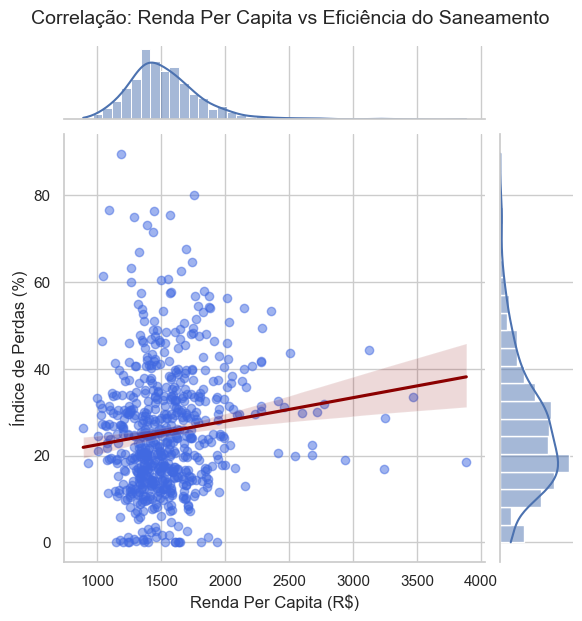

In [171]:
# Criando o jointplot e armazenando em uma variável 'g'
g = sns.jointplot(
    data=df_final, 
    x='renda_per_capita', 
    y='indice_perdas_distribuicao', 
    kind='reg', 
    scatter_kws={'alpha': 0.5, 'color': 'royalblue'}, 
    line_kws={'color': 'darkred'}
)

# Ajustando o título corretamente utilizando a API do JointGrid para evitar sobreposições
g.fig.suptitle('Correlação: Renda Per Capita vs Eficiência do Saneamento', y=1.03, fontsize=14)
g.set_axis_labels('Renda Per Capita (R$)', 'Índice de Perdas (%)', fontsize=12)

plt.show()

### Interpretação da relação entre renda e perdas

A linha de tendência exibe uma leve inclinação positiva, indicando que, na base bruta, municípios com maior renda per capita apresentam, em média, índices de perdas ligeiramente superiores ou estáveis.

Os histogramas marginais também revelam uma forte assimetria à direita na renda per capita, mostrando que a grande maioria das cidades paulistas concentra-se em patamares de menor renda (abaixo de R$ 2.000) e perdas concentradas na faixa de 20% a 40%.

## 19. Matriz de Média de Perdas por Natureza Jurídica e Tipo de Serviço

Este código tem o objetivo de estruturar e visualizar uma tabela dinâmica em formato de mapa de calor (heatmap) cruzando a natureza jurídica dos prestadores com o tipo de serviço prestado. O gráfico exibe os valores médios do índice de perdas de água para cada categoria, permitindo identificar quais modelos de gestão e escopos de atendimento apresentam maior ou menor eficiência hídrica no estado.

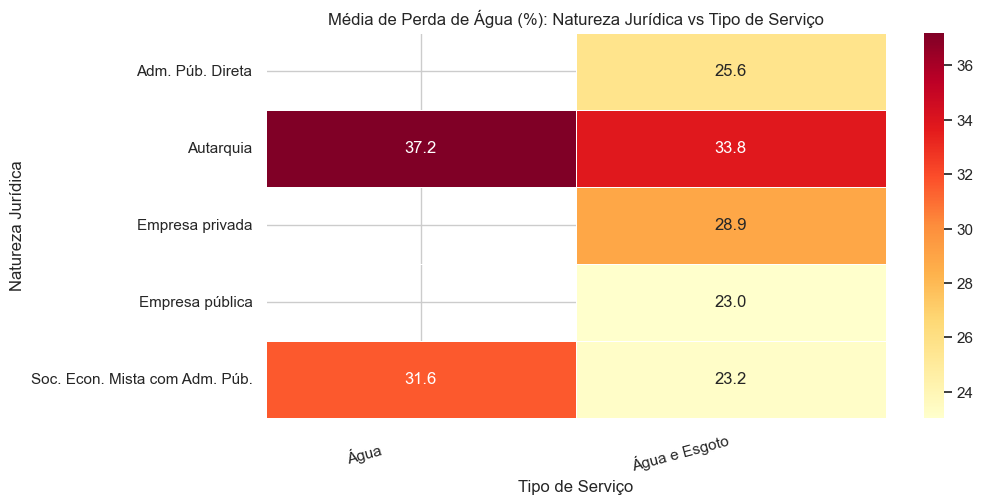

In [172]:
# Cria uma tabela dinâmica calculando a média de perda de água para cada cruzamento
tabela_cruzada = pd.pivot_table(
    data=df_final, 
    values='indice_perdas_distribuicao', 
    index='natureza_juridica', 
    columns='tipo_servico', 
    aggfunc='mean'
)

plt.figure(figsize=(10, 5))
sns.heatmap(tabela_cruzada, annot=True, cmap='YlOrRd', fmt=".1f", linewidths=0.5)
plt.title('Média de Perda de Água (%): Natureza Jurídica vs Tipo de Serviço')
plt.ylabel('Natureza Jurídica')
plt.xlabel('Tipo de Serviço')
plt.xticks(rotation=15, ha='right')
plt.show()

### Interpretação do mapa de calor

As autarquias dedicadas exclusivamente ao serviço de água apresentam a maior taxa média de perdas do estado (37,2%), destacando-se no topo da escala de cores (tons mais escuros), além na prestação conjunta de "Água e Esgoto" com 33,8%.

As categorias de empresas públicas e sociedades de economia mista focadas na prestação conjunta de "Água e Esgoto" registram os menores índices médios de perdas (em torno de 23%), sugerindo maior eficiência nesses arranjos.

Os espaços em branco na matriz representam cruzamentos ausentes ou não reportados no SNIS para o estado.

## 20. Zonas de Densidade Bivariada: Risco Climático e Ineficiência Operacional

Este código tem o objetivo de gerar um gráfico de densidade bivariada (2D KDE com preenchimento em formato de contorno) para mapear a concentração de municípios em função de sua exposição a períodos de seca extrema (CDD) e do índice de perdas na distribuição de água. A visualização permite identificar visualmente as zonas de maior aglomeração de cidades que compartilham níveis semelhantes de vulnerabilidade climática e ineficiência operacional no saneamento.

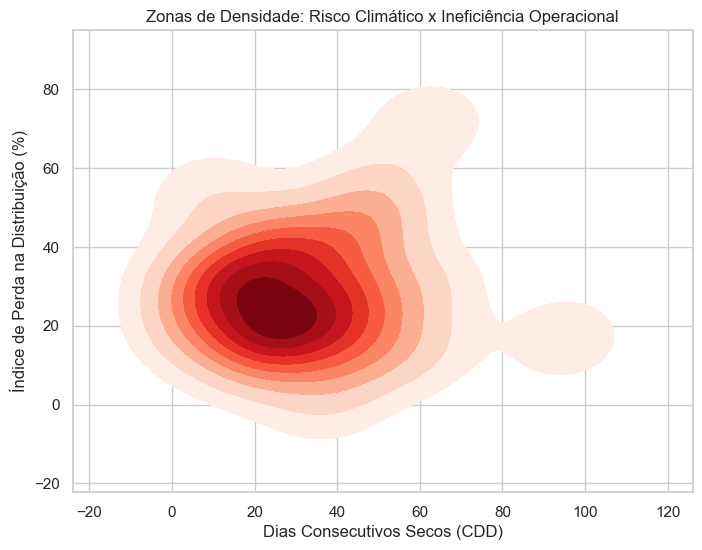

In [173]:
plt.figure(figsize=(8, 6))
sns.kdeplot(
    data=df_final, 
    x='max_dias_consecutivos_seca', 
    y='indice_perdas_distribuicao', 
    fill=True, 
    cmap='Reds', 
    thresh=0.05
)
plt.title('Zonas de Densidade: Risco Climático x Ineficiência Operacional')
plt.xlabel('Dias Consecutivos Secos (CDD)')
plt.ylabel('Índice de Perda na Distribuição (%)')
plt.show()

### Interpretação da densidade bivariada

O núcleo central mais escuro (vermelho profundo) indica que a grande maioria das cidades paulistas se agrupa em uma faixa de 20 a 40 dias consecutivos secos e índices de perdas situados entre 20% e 40%.

As curvas de contorno mostram uma distribuição unimodal principal com caudas que se estendem em direção a maiores índices de perda e a períodos de seca mais longos (acima de 60 dias).

## 21. Gráfico de Dispersão Tridimensional da Vulnerabilidade Hídrica

Este código tem o objetivo de construir um gráfico de dispersão em 3D para mapear simultaneamente as três dimensões centrais da vulnerabilidade municipal: renda per capita no eixo X, índice de perdas de água no eixo Y e dias consecutivos secos no eixo Z. A visualização utiliza uma paleta de cores contínua baseada no nível de perdas para realçar a intensidade da ineficiência operacional ao longo do espaço tridimensional das variáveis.

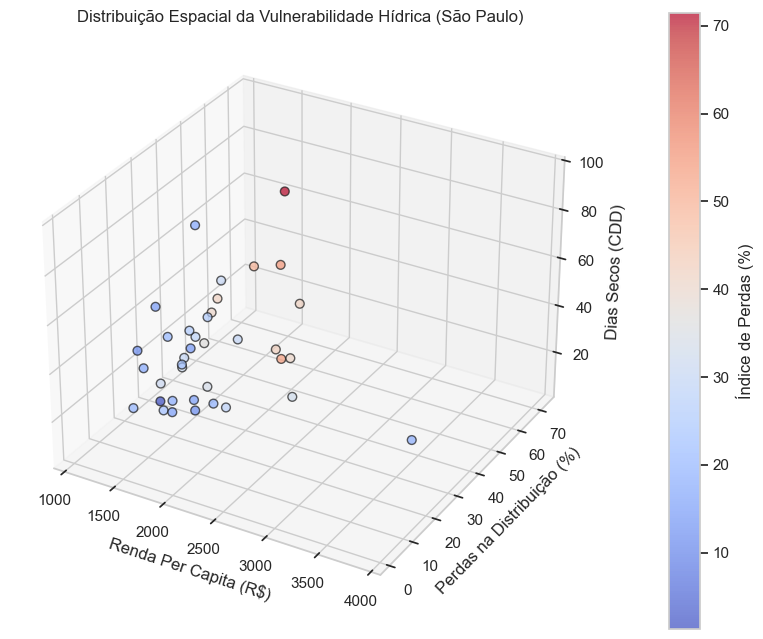

In [174]:
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')

# Eixos x (Renda), y (Perda), z (Clima)
x = df_final['renda_per_capita']
y = df_final['indice_perdas_distribuicao']
z = df_final['max_dias_consecutivos_seca']

# O mapa de cores (cmap) reforça visualmente o eixo da ineficiência
scatter = ax.scatter(x, y, z, c=y, cmap='coolwarm', alpha=0.7, s=40, edgecolors='k')

ax.set_xlabel('Renda Per Capita (R$)')
ax.set_ylabel('Perdas na Distribuição (%)')
ax.set_zlabel('Dias Secos (CDD)')
ax.set_title('Distribuição Espacial da Vulnerabilidade Hídrica (São Paulo)')

plt.colorbar(scatter, label='Índice de Perdas (%)', pad=0.1)
plt.show()

### Interpretação do gráfico 3D

A grande maioria dos municípios com dados climáticos integrados concentra-se em faixas de renda mais baixas (entre R$ 1.200 e R$ 2.000) e com períodos de seca intermediários (20 a 40 dias).

O espaço tridimensional revela que altos índices de perdas (tons avermelhados) não estão restritos a uma única faixa de renda ou de dias secos, espalhando-se de forma heterogênea pelo gráfico.

## 22. Teste Estatístico de Kruskal-Wallis entre Perdas e Natureza Jurídica

Este código tem o objetivo de aplicar o teste não paramétrico de Kruskal-Wallis para verificar se existem diferenças estatisticamente significativas nos índices de perdas de água entre os municípios, agrupando-os conforme a natureza jurídica de seus prestadores de saneamento. A rotina separa as amostras por categoria de gestão, calcula a estatística $H$ e o $p$-valor correspondente, e emite uma conclusão automática para subsidiar a validação das hipóteses do estudo.

In [175]:
# Filtra os dados removendo categorias vazias ou muito pequenas
df_teste = df_final.dropna(subset=['natureza_juridica', 'indice_perdas_distribuicao'])
categorias = [grupo['indice_perdas_distribuicao'].values for nome, grupo in df_teste.groupby('natureza_juridica')]

# Aplica o teste de Kruskal-Wallis
estatistica, p_valor = stats.kruskal(*categorias)

print("=== Teste de Kruskal-Wallis (Perdas vs Natureza Jurídica) ===")
print(f"Estatística H: {estatistica:.2f}")
print(f"P-valor: {p_valor:.4e}")

if p_valor < 0.05:
    print("-> Conclusão: Há diferença estatisticamente significativa nas perdas de água entre os diferentes tipos de gestão.")
else:
    print("-> Conclusão: Não há evidências de que o tipo de gestão afeta significativamente as perdas.")

=== Teste de Kruskal-Wallis (Perdas vs Natureza Jurídica) ===
Estatística H: 33.58
P-valor: 9.1045e-07
-> Conclusão: Há diferença estatisticamente significativa nas perdas de água entre os diferentes tipos de gestão.


### Interpretação do teste de Kruskal-Wallis

O teste apresentou estatística **H = 33,58** e **p-valor = 9,1045 × 10⁻⁷**. Como o p-valor é menor que 0,05, rejeita-se a hipótese de que todos os grupos de natureza jurídica possuem a mesma distribuição de perdas.

Assim, há evidência estatística de diferença nas perdas de água entre os modelos de gestão. O teste identifica que existe diferença entre pelo menos dois grupos, mas não informa sozinho quais pares são diferente, uma análise pós-hoc seria necessária para localizar essas diferenças.

## 23. Renderização Cartográfica Tripla da Vulnerabilidade Municipal

Este código tem o objetivo de baixar a malha geográfica vetorial oficial do estado de São Paulo diretamente da API do IBGE, padronizar as chaves de identificação municipal e realizar a junção espacial (left join) com a base de dados consolidada. Em seguida, o script gera um painel cartográfico composto por três mapas coropléticos lado a lado, representando a distribuição espacial da renda per capita, do índice de perdas de água e do risco climático de seca no estado.

Baixando malha completa de SP do IBGE...
Municípios na malha: 645
Municípios com dados de renda integrados: 643


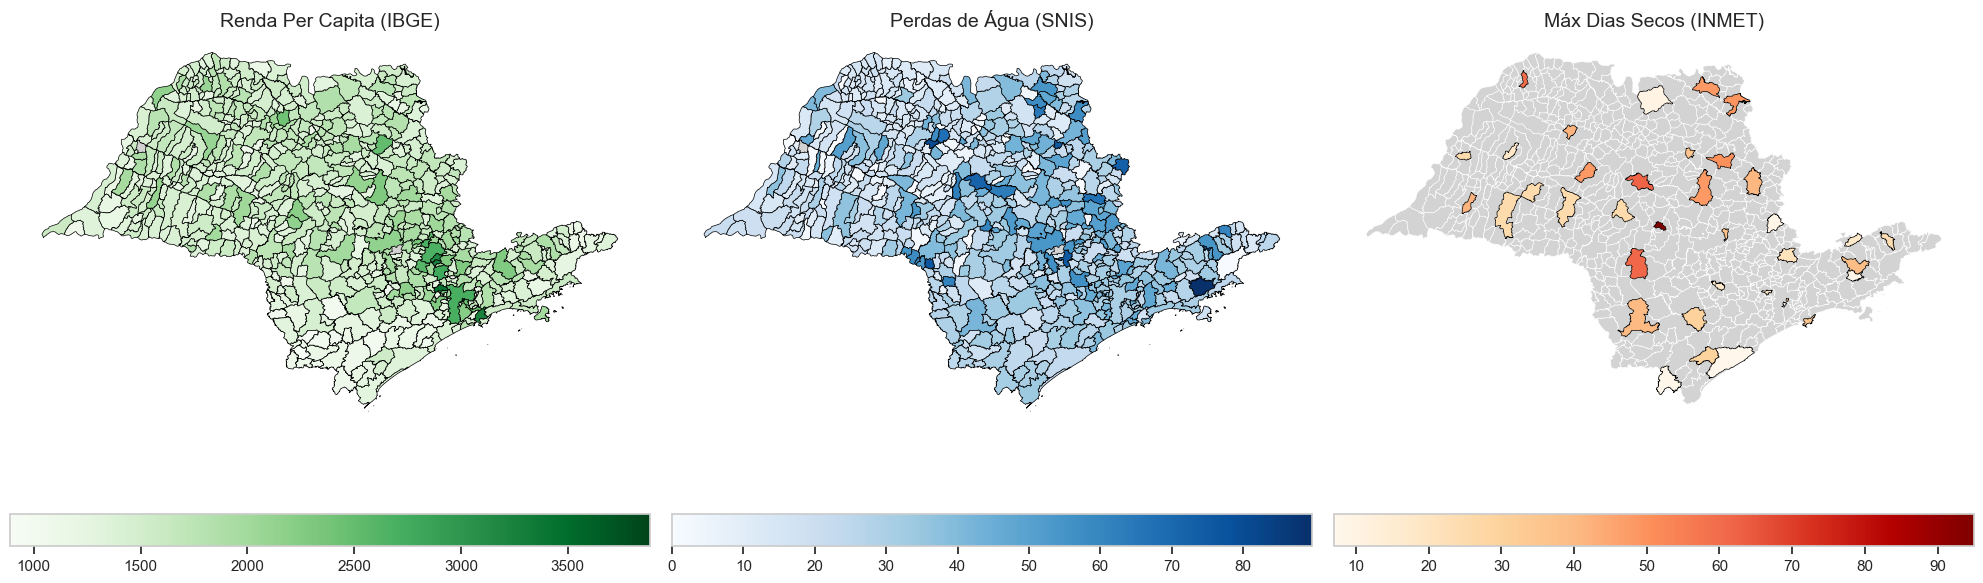

In [176]:
# 1. Requisição explícita via requests para evitar bloqueios da API
url_todas_cidades_sp = "https://servicodados.ibge.gov.br/api/v3/malhas/estados/35?resolucao=5&intrarregiao=municipio&formato=application/vnd.geo+json"

print("Baixando malha completa de SP do IBGE...")
resposta = requests.get(url_todas_cidades_sp, timeout=60)
resposta.raise_for_status()  # Trava o código e avisa se o IBGE estiver fora do ar

# 2. Conversão segura do JSON para GeoDataFrame
mapa_sp = gpd.GeoDataFrame.from_features(resposta.json()["features"])

# 3. Padronização da chave de união (garantindo 6 dígitos em formato texto)
mapa_sp['id_join'] = mapa_sp['codarea'].astype(str).str[:6]
df_final['id_join'] = df_final['id_municipio'].astype(str).str[:6]

# 4. Merge Left: Mantém o mapa intacto e anexa os dados onde houver correspondência
mapa_dados = mapa_sp.merge(df_final, on='id_join', how='left')

print(f"Municípios na malha: {len(mapa_sp)}")
print(f"Municípios com dados de renda integrados: {mapa_dados['renda_per_capita'].notna().sum()}")

# 5. Renderizando os mapas (Fundo cinza + Dados coloridos)
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

for ax in axes:
    ax.axis('off')

# Mapa 1: Renda
mapa_dados.plot(ax=axes[0], color='lightgrey', edgecolor='white', linewidth=0.4) 
mapa_dados.dropna(subset=['renda_per_capita']).plot(
    column='renda_per_capita', cmap='Greens', linewidth=0.5, edgecolor='black', 
    legend=True, legend_kwds={'orientation': "horizontal"}, ax=axes[0]
)
axes[0].set_title('Renda Per Capita (IBGE)', fontsize=14)

# Mapa 2: Perdas
mapa_dados.plot(ax=axes[1], color='lightgrey', edgecolor='white', linewidth=0.4) 
mapa_dados.dropna(subset=['indice_perdas_distribuicao']).plot(
    column='indice_perdas_distribuicao', cmap='Blues', linewidth=0.5, edgecolor='black', 
    legend=True, legend_kwds={'orientation': "horizontal"}, ax=axes[1]
)
axes[1].set_title('Perdas de Água (SNIS)', fontsize=14)

# Mapa 3: Clima
mapa_dados.plot(ax=axes[2], color='lightgrey', edgecolor='white', linewidth=0.4) 
mapa_dados.dropna(subset=['max_dias_consecutivos_seca']).plot(
    column='max_dias_consecutivos_seca', cmap='OrRd', linewidth=0.5, edgecolor='black', 
    legend=True, legend_kwds={'orientation': "horizontal"}, ax=axes[2]
)
axes[2].set_title('Máx Dias Secos (INMET)', fontsize=14)

plt.tight_layout()
plt.show()

### Interpretação dos mapas temáticos

A malha contém **645 municípios**, dos quais **643 possuem dados de renda integrados**. Os mapas permitem comparar espacialmente renda, perdas de água e dias secos, mantendo os municípios sem informação em uma camada neutra.

A visualização evidencia que os indicadores não são uniformes no território. A comparação espacial ajuda a localizar municípios que combinam baixa renda, perdas elevadas ou maior exposição à seca.

## 24. Mapeamento Categórico dos Modelos de Gestão de Saneamento

Este código tem o objetivo de renderizar um mapa coroplético unificado do estado de São Paulo, destacando a distribuição geográfica dos diferentes modelos de gestão de saneamento de acordo com a natureza jurídica dos prestadores. A rotina utiliza uma camada base em cinza claro para preencher todo o território municipal e sobrepõe os dados categóricos utilizando uma paleta de cores distinta (tab10) para evitar conflitos visuais e assegurar a legibilidade das legendas.

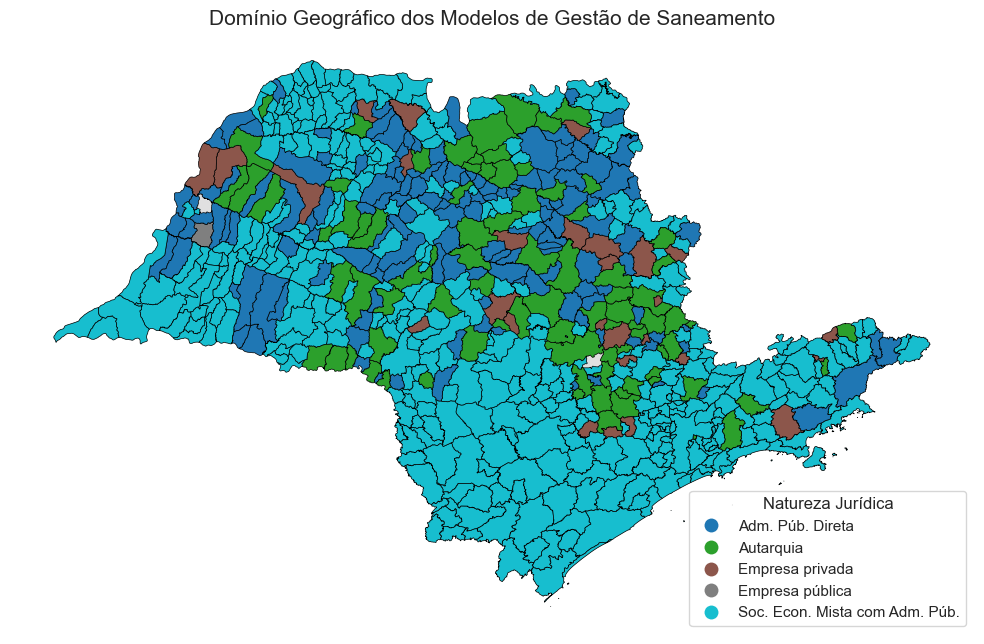

,Quantidade (Municípios),Porcentagem (%)
natureza_juridica,,
Soc. Econ. Mista com Adm. Púb.,379,58.94
Adm. Púb. Direta,150,23.33
Autarquia,85,13.22
Empresa privada,28,4.35
Empresa pública,1,0.16


In [180]:
fig, ax = plt.subplots(1, 1, figsize=(10, 8))
ax.axis('off')

# 1. Camada Base: Fundo do estado em cinza bem clarinho
mapa_dados.plot(ax=ax, color='#e0e0e0', edgecolor='white', linewidth=0.4)

# 2. Camada de Dados: Usando a paleta 'tab10' para evitar o cinza
mapa_dados.dropna(subset=['natureza_juridica']).plot(
    column='natureza_juridica', 
    categorical=True, 
    cmap='tab10', # <-- Troca da paleta aqui
    linewidth=0.5, 
    edgecolor='black', 
    legend=True,
    legend_kwds={'loc': 'lower right', 'title': 'Natureza Jurídica'},
    ax=ax
)

ax.set_title('Domínio Geográfico dos Modelos de Gestão de Saneamento', fontsize=15)
plt.tight_layout()
plt.show()

# Calculando a contagem absoluta e a porcentagem de cada modelo de gestão
contagem = df_final['natureza_juridica'].value_counts()
porcentagem = df_final['natureza_juridica'].value_counts(normalize=True) * 100

df_distribuicao = pd.DataFrame({
    'Quantidade (Municípios)': contagem,
    'Porcentagem (%)': porcentagem.round(2)
})

display(df_distribuicao)

### Interpretação do mapa de modelos de gestão

Observa-se uma vasta predominância da cor azul-clara (Sociedade de Economia Mista com Administração Pública, onde tipicamente se insere a atuação da Sabesp e grandes operadoras) cobrindo grande parte do território paulista, especialmente nas regiões central, sul e leste.

A categoria de autarquias (representada em verde) concentra-se expressivamente em regiões específicas, formando manchas contínuas que indicam forte adesão ao modelo de gestão pública direta ou autárquica municipal em detrimento da concessão regionalizada.

Os registros de empresas privadas (marrom) e administração pública direta (azul escuro) aparecem de forma mais pontual e isolada em municípios específicos, evidenciando a diversidade institucional na prestação dos serviços de saneamento básico no estado.

Ao verificar a tabela gerada, podemos ter uma noção mais exata de tudo isso:

- A categoria de Sociedade de Economia Mista com Administração Pública lidera com folga o estado, cobrindo 58.94% dos municípios analisados, o que reflete a forte capilaridade de grandes operadoras integradas (como a Sabesp).

- As Autarquias e a Administração Pública Direta somam juntas cerca de 36.55% das cidades, demonstrando que mais de um terço dos municípios opta por gerir os serviços de saneamento por dentro da estrutura da própria administração municipal.

- As Empresas privadas representam apenas 4.35% dos municípios, enquanto as Empresas públicas registram uma presença pontual e residual na amostra (0.16%).

## 25. Normalização Z-Score e Comparação de Distribuições Numéricas

Este código tem o objetivo de aplicar a padronização por Z-score nas variáveis numéricas brutas do estudo: renda per capita, índice de perdas de água e máximo de dias secos. E gerar um painel gráfico comparativo de densidade (KDE). A rotina transforma as escalas originais (utilizando uma escala logarítmica no gráfico prévio para visualização) para colocar todas as dimensões em uma mesma base de desvios padrão, garantindo pesos equivalentes nas análises multivariadas e nos modelos subsequentes.

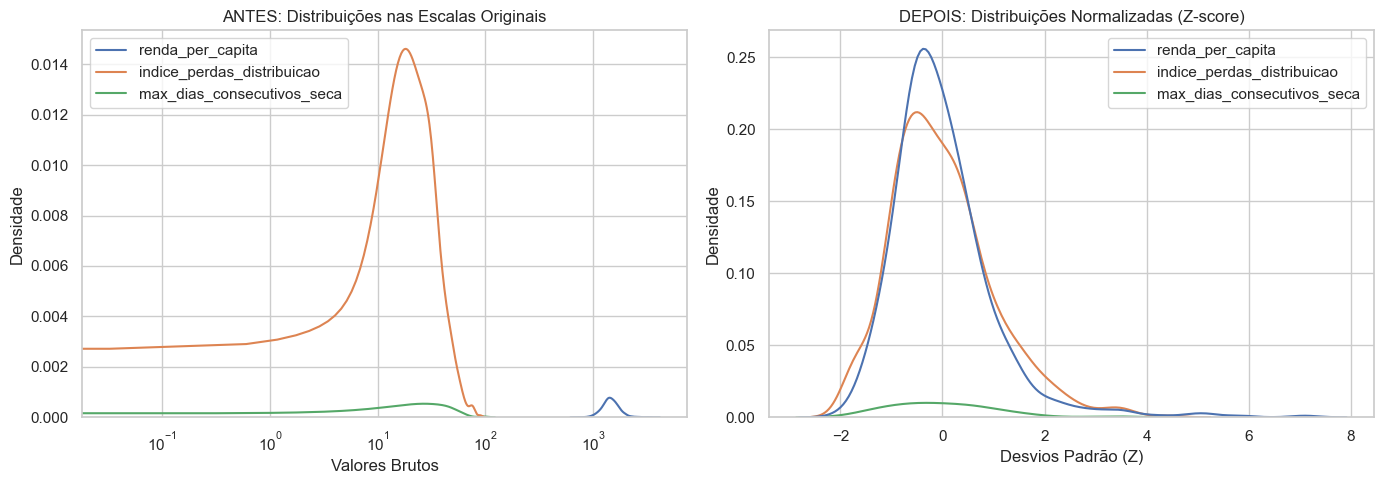

In [178]:
# Variáveis numéricas brutas
colunas = ['renda_per_capita', 'indice_perdas_distribuicao', 'max_dias_consecutivos_seca']
df_bruto = df_final[colunas].copy()

# Aplicando Z-score
scaler = StandardScaler()
df_norm = pd.DataFrame(scaler.fit_transform(df_bruto), columns=colunas)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Gráfico 1: Antes da Normalização (Escalas originais)
sns.kdeplot(data=df_bruto, ax=axes[0])
axes[0].set_title('ANTES: Distribuições nas Escalas Originais')
axes[0].set_ylabel('Densidade')
axes[0].set_xlabel('Valores Brutos')
axes[0].set_xscale('log') # Escala logarítmica apenas para caber no mesmo gráfico bruto

# Gráfico 2: Depois da Normalização (Mesma escala)
sns.kdeplot(data=df_norm, ax=axes[1])
axes[1].set_title('DEPOIS: Distribuições Normalizadas (Z-score)')
axes[1].set_ylabel('Densidade')
axes[1].set_xlabel('Desvios Padrão (Z)')

plt.tight_layout()
plt.show()

### Interpretação da normalização

A normalização por Z-score coloca renda, perdas de água e dias secos em uma escala comum, com média próxima de zero e desvio padrão próximo de um. Isso evita que a renda, por possuir valores numericamente maiores, domine automaticamente as análises multivariadas ou os algoritmos de clusterização.

O gráfico compara as distribuições antes e depois da transformação. Após a normalização, as variáveis podem ser comparadas pelo afastamento em desvios padrão, preservando a posição relativa dos municípios dentro de cada indicador.